# IE 7615 -Discriminative Project, Milestone 2 (Group 4)
### Multi-object detection with YOLOv8s

## 1. Setup

In [1]:
%pip -q install ultralytics

import os, random, re, hashlib, zipfile, shutil
from pathlib import Path
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import yaml
from ultralytics import YOLO

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
ROOT = Path('/content/milestone2')
ROOT.mkdir(exist_ok=True)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 26.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 7.1 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## 2. Load the dataset

In [2]:
from google.colab import files

zips = sorted(Path('/content').glob('*.zip'), key=lambda p: p.stat().st_mtime)
if not zips:
    uploaded = files.upload()
    zips = [Path('/content') / name for name in uploaded if name.lower().endswith('.zip')]
if not zips:
    raise FileNotFoundError('Upload the full shared dataset ZIP, not just OBJ010.')

zip_path = zips[-1]
source_dir = ROOT / 'source'
if source_dir.exists():
    shutil.rmtree(source_dir)
source_dir.mkdir(parents=True)
with zipfile.ZipFile(zip_path) as archive:
    archive.extractall(source_dir)

possible = []
for folder in [source_dir, *source_dir.rglob('*')]:
    if folder.is_dir():
        n = sum(bool(re.fullmatch(r'images_OBJ\d+', p.name, re.I)) for p in folder.iterdir() if p.is_dir())
        if n:
            possible.append((n, folder))
if not possible:
    raise RuntimeError('Could not find the images_OBJ### folders in the ZIP.')
data_dir = max(possible, key=lambda item: item[0])[1]
print('Dataset:', data_dir)


Saving IE7615 Deep Learning for AI-20261004T181616Z-1-001.zip to IE7615 Deep Learning for AI-20261004T181616Z-1-001.zip
Dataset: /content/milestone2/source/IE7615 Deep Learning for AI


## 3. Clean and split the source photos
We exclude the `_bg_` photos, unreadable files, and exact duplicates before splitting the source photos.

In [3]:
classes = sorted(p.name for p in data_dir.iterdir()
                 if p.is_dir() and re.fullmatch(r'images_OBJ\d+', p.name, re.I))
class_id = {name: i for i, name in enumerate(classes)}
source_split = {'train': {}, 'val': {}, 'test': {}}
removed_bg = removed_duplicate = removed_bad = 0
rng = random.Random(SEED)

for cls in classes:
    images = []
    fingerprints = set()
    for path in sorted((data_dir / cls).iterdir()):
        if not path.is_file() or path.suffix.lower() not in {'.jpg', '.jpeg', '.png'}:
            continue
        if re.search(r'_bg_|background', path.stem, re.I):
            removed_bg += 1
            continue
        try:
            with Image.open(path) as im:
                im.verify()
            digest = hashlib.md5(path.read_bytes()).hexdigest()
            if digest in fingerprints:
                removed_duplicate += 1
                continue
            fingerprints.add(digest)
            images.append(path)
        except Exception:
            removed_bad += 1
    rng.shuffle(images)
    if len(images) < 10:
        raise ValueError(f'{cls}: not enough usable images ({len(images)})')
    n_train = int(len(images) * 0.70)
    n_val = int(len(images) * 0.15)
    source_split['train'][cls] = images[:n_train]
    source_split['val'][cls] = images[n_train:n_train+n_val]
    source_split['test'][cls] = images[n_train+n_val:]

print(f'{len(classes)} classes | {sum(len(source_split[s][c]) for s in source_split for c in classes)} usable source photos')
print(f'Excluded: {removed_bg} background-only, {removed_duplicate} exact duplicates, {removed_bad} unreadable')
print('Usable source photos by split:', {s: sum(len(v) for v in source_split[s].values()) for s in source_split})


73 classes | 6948 usable source photos
Excluded: 379 background-only, 16 exact duplicates, 0 unreadable
Usable source photos by split: {'train': 4828, 'val': 1020, 'test': 1100}


## 4. Create multi-object images and YOLO labels

Our original code labeled each object with a box that was just
the entire grid tile it was pasted into, not the object itself.
This meant our model was learning "which cell is this object in" instead of real object localization, and it's why our old mAP@50 and mAP@50-95 scores were nearly identical (both ~94%), which is a sign the boxes were too easy to match, not a sign the model was actually good at precise localization.

The functions below fix this by detecting where the object actually sits in each photo (using simple background-contrast detection) and writing that as the bounding box instead.

In [4]:
N_IMAGES = {'train': 420, 'val': 90, 'test': 90}  # 600 total; half 2x2 and half 3x3
CANVAS = 640
output = ROOT / 'yolo_dataset'
if output.exists():
    shutil.rmtree(output)
for split in N_IMAGES:
    (output / 'images' / split).mkdir(parents=True)
    (output / 'labels' / split).mkdir(parents=True)

# Shuffle a deck of class IDs so all classes are sampled regularly.
def class_deck(rng):
    while True:
        deck = list(range(len(classes)))
        rng.shuffle(deck)
        yield from deck

# UPDATED TO CREATE TIGHTER BOUNDING BOXES
# instead of having the bounding box be the entire tile
# we try to detect where the actual object sits within each photo
# first estimate_background_stats reads the image and looks at the border
# pixels to guess the background. This then returns how varied and noisy the
# background image is (the standard dev) instead of just the typical brightness
def estimate_background_stats(gray_array):

    border_pixels = np.concatenate([
        gray_array[0, :],
        gray_array[-1, :],
        gray_array[:, 0],
        gray_array[:, -1],
    ])
    return np.median(border_pixels), np.std(border_pixels)

# Here we are finding a tight box around the object
# It looks at how nosiy each photo's own bakground is and sets the
# threshold relative to that. For example an image with a plain and simple
# background would have a lower threshold (more strict)in order for
# small objects to still get recognized. A photo that has a busier and or
# textured background will have a less strict threshold.


# pad_frac--> padding margin added around the detected object

# min_frac --> smallest allowed object size (as a fraction of
# the whole image) before we give up and use the full tile instead.
# Lowered from before, so small objects aren't incorrectly treated as
# "detection failed

# max_frac --> largest allowed object size before we give up
# (protects against treating the WHOLE photo as "the object," which
# usually means detection broke)---> this is what our previous model was doing

# k --> how many standard deviations above the background's natural noise
# counts as "different enough to be the object-->  higher = stricter

# min_diff --> an absolute minimum threshold, so that even on a perfectly f
# flat simple background we don't become overly sensitive to tiny noise

def get_tight_box(im, pad_frac=0.03, min_frac=0.002, max_frac=0.99,
                   k=2.5, min_diff=10):

    gray = np.array(im.convert('L'), dtype=np.float32)
    h, w = gray.shape

    bg_median, bg_std = estimate_background_stats(gray)
    threshold = max(min_diff, k * bg_std)

    diff = np.abs(gray - bg_median)
    mask = diff > threshold

    ys, xs = np.where(mask)

    min_pixels = min_frac * w * h
    max_pixels = max_frac * w * h
    if len(xs) < min_pixels or len(xs) > max_pixels:
        return 0, 0, w, h  # fallback is to use the full image

    x0, x1 = int(xs.min()), int(xs.max()) + 1
    y0, y1 = int(ys.min()), int(ys.max()) + 1

    pad_x = int(round((x1 - x0) * pad_frac))
    pad_y = int(round((y1 - y0) * pad_frac))
    x0 = max(0, x0 - pad_x)
    y0 = max(0, y0 - pad_y)
    x1 = min(w, x1 + pad_x)
    y1 = min(h, y1 + pad_y)

    return x0, y0, x1, y1

# compute_fit_crop does what ImageOps.fit() before resizing as it
# center crops the source photo so its aspect ratio matches the target tiles
# aspect ratio
# we must know what exact region ImageOps.fit() cropped out so we correclty
# map our tight obeject box  into the final tile coordiantes
def compute_fit_crop(src_w, src_h, target_w, target_h):

    src_ratio = src_w / src_h
    target_ratio = target_w / target_h

    if src_ratio > target_ratio:
        # Source photo is relatively wider than the tile needs
        # so ImageOps.fit() crops off the left/right edges
        new_w = int(round(src_h * target_ratio))
        new_h = src_h
        crop_x0 = (src_w - new_w) // 2
        crop_y0 = 0
    else:
        # Source photo is relatively taller than the tile needs
        # so ImageOps.fit() crops off the top/bottom edges
        new_w = src_w
        new_h = int(round(src_w / target_ratio))
        crop_x0 = 0
        crop_y0 = (src_h - new_h) // 2

    crop_x1 = crop_x0 + new_w
    crop_y1 = crop_y0 + new_h
    return crop_x0, crop_y0, crop_x1, crop_y1


# NEW make_composite() —-> now writes tight boxes instead of tiles

def make_composite(split, grid_size, deck, rng):
    n_cells = grid_size ** 2
    n_objects = n_cells
    chosen = []
    while len(chosen) < n_objects:
        cls_index = next(deck)
        if cls_index not in chosen:
            chosen.append(cls_index)
    positions = rng.sample(range(n_cells), n_objects)
    canvas = Image.new('RGB', (CANVAS, CANVAS), (225, 225, 225))
    labels = []

    for cls_index, pos in zip(chosen, positions):
        cls = classes[cls_index]
        photo = rng.choice(source_split[split][cls])
        row, col = divmod(pos, grid_size)

        #  Tile boundaries in the final composite canvas
        x0 = round(col * CANVAS / grid_size)
        x1 = round((col + 1) * CANVAS / grid_size)
        y0 = round(row * CANVAS / grid_size)
        y1 = round((row + 1) * CANVAS / grid_size)
        tile_w, tile_h = x1 - x0, y1 - y0

        with Image.open(photo) as im:
            im = im.convert('RGB')
            src_w, src_h = im.size

            #finds the tight object box in the og photo
            obj_x0, obj_y0, obj_x1, obj_y1 = get_tight_box(im)

            # figure out what region ImageOps.fit() will crop
            # (this must match exactly what ImageOps.fit does below)
            crop_x0, crop_y0, crop_x1, crop_y1 = compute_fit_crop(
                src_w, src_h, tile_w, tile_h
            )

            # clip the tight object box to that crop region
            # (if the object box extends outside the crop, the cropped-off
            # part isn't visible in the final tile anyway, so we clip it)
            clipped_x0 = max(obj_x0, crop_x0)
            clipped_y0 = max(obj_y0, crop_y0)
            clipped_x1 = min(obj_x1, crop_x1)
            clipped_y1 = min(obj_y1, crop_y1)

            # Safety fallback--> if clipping produced an invalid/empty box
            # just use the full crop region —->  equivalent to our previous models
            # "whole tile" behavior
            if clipped_x1 <= clipped_x0 or clipped_y1 <= clipped_y0:
                clipped_x0, clipped_y0 = crop_x0, crop_y0
                clipped_x1, clipped_y1 = crop_x1, crop_y1

            # convert to relative to the crop coordinates
            rel_x0 = clipped_x0 - crop_x0
            rel_y0 = clipped_y0 - crop_y0
            rel_x1 = clipped_x1 - crop_x0
            rel_y1 = clipped_y1 - crop_y0

            # scale from crop size -> actual tile pixel size
            crop_w = crop_x1 - crop_x0
            crop_h = crop_y1 - crop_y0
            scale_x = tile_w / crop_w
            scale_y = tile_h / crop_h

            tile_box_x0 = rel_x0 * scale_x
            tile_box_y0 = rel_y0 * scale_y
            tile_box_x1 = rel_x1 * scale_x
            tile_box_y1 = rel_y1 * scale_y

            # shift into the FULL composite canvas coordinates
            # (x0, y0 here are the tile's top-left corner in the full canvas)
            final_box_x0 = x0 + tile_box_x0
            final_box_y0 = y0 + tile_box_y0
            final_box_x1 = x0 + tile_box_x1
            final_box_y1 = y0 + tile_box_y1

            # Paste the photo into the canvas
            tile = ImageOps.fit(im, (tile_w, tile_h), method=Image.Resampling.LANCZOS)
            canvas.paste(tile, (x0, y0))

        #  Write the tight box  to the YOLO label
        xc = (final_box_x0 + final_box_x1) / (2 * CANVAS)
        yc = (final_box_y0 + final_box_y1) / (2 * CANVAS)
        w = (final_box_x1 - final_box_x0) / CANVAS
        h = (final_box_y1 - final_box_y0) / CANVAS
        labels.append(f'{cls_index} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}')

    return canvas, labels

for split, count in N_IMAGES.items():
    deck = class_deck(rng)
    grids = [2] * (count // 2) + [3] * (count - count // 2)
    rng.shuffle(grids)
    for i, grid_size in enumerate(grids):
        image, labels = make_composite(split, grid_size, deck, rng)
        stem = f'{split}_{i:04d}_{grid_size}x{grid_size}'
        image.save(output / 'images' / split / f'{stem}.jpg', quality=92)
        (output / 'labels' / split / f'{stem}.txt').write_text('\n'.join(labels) + '\n')

config = {'path': str(output), 'train': 'images/train', 'val': 'images/val',
          'test': 'images/test', 'nc': len(classes), 'names': classes}
config_path = ROOT / 'dataset.yaml'
config_path.write_text(yaml.safe_dump(config, sort_keys=False))
print('YOLO images:', N_IMAGES)
print('2x2 and 3x3 layouts: 300 each')
print('Number of classes:', len(classes))
print('Configuration:', config_path)


YOLO images: {'train': 420, 'val': 90, 'test': 90}
2x2 and 3x3 layouts: 300 each
Number of classes: 73
Configuration: /content/milestone2/dataset.yaml


## 5. Check two example images and their bounding boxes

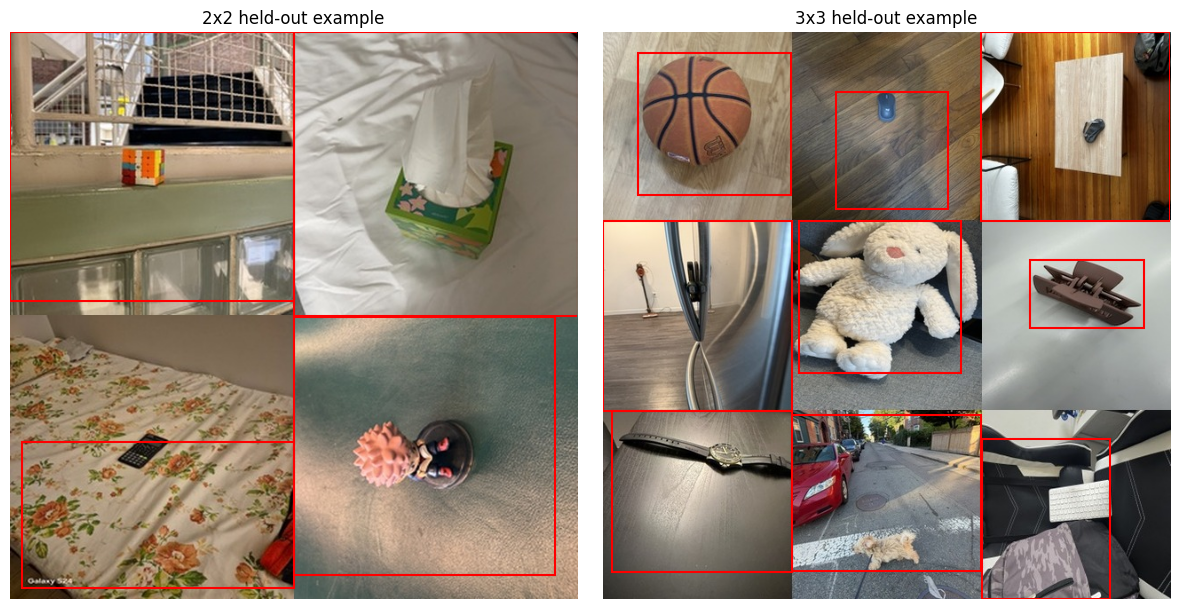

In [5]:
import matplotlib.patches as patches

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, grid_size in zip(axes, [2, 3]):
    example = sorted((output / 'images' / 'test').glob(f'*_{grid_size}x{grid_size}.jpg'))[0]
    with Image.open(example) as im:
        ax.imshow(im)
    label_path = output / 'labels' / 'test' / (example.stem + '.txt')
    for line in label_path.read_text().splitlines():
        cls, xc, yc, w, h = map(float, line.split())
        x = (xc-w/2)*CANVAS
        y = (yc-h/2)*CANVAS
        ax.add_patch(patches.Rectangle((x,y), w*CANVAS, h*CANVAS,
                                       linewidth=1.5, edgecolor='red', facecolor='none'))
    ax.set_title(f'{grid_size}x{grid_size} held-out example')
    ax.axis('off')
plt.tight_layout()
plt.show()


## 6. Train YOLOv8s

In [6]:
model = YOLO('yolov8s.pt')
model.train(data=str(config_path), epochs=40, imgsz=640, batch=16,
            patience=10, seed=SEED, device=0, workers=2,
            project=str(ROOT / 'runs'), name='yolov8s_milestone2',
            exist_ok=True, plots=True)


Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/milestone2/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_milestone2, nbs=64, nms=None, opset=None, optimiz

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7980344f6e40>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0

## 7. Evaluate on the held-out test images

In [7]:
best_path = ROOT / 'runs' / 'yolov8s_milestone2' / 'weights' / 'best.pt'
if not best_path.exists():
    raise FileNotFoundError('Training did not produce best.pt; check the training cell.')
best_model = YOLO(str(best_path))
metrics = best_model.val(data=str(config_path), split='test', imgsz=640, batch=16,
                         device=0, plots=True)
print(f'Precision: {metrics.box.mp:.4f}')
print(f'Recall: {metrics.box.mr:.4f}')
print(f'mAP@50: {metrics.box.map50:.4f}')
print(f'mAP@50-95: {metrics.box.map:.4f}')


Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,153,835 parameters, 0 gradients, 28.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 16.5±2.4 MB/s, size: 123.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/milestone2/yolo_dataset/labels/test... 90 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 90/90 399.2it/s 0.2s
val: New cache created: /content/milestone2/yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.7it/s 3.6s
                   all         90        585       0.71      0.678      0.719      0.517
         images_OBJ001          8          8      0.754      0.766      0.779      0.427
         images_OBJ002          8          8      0.796      0.875      0.859     

In [8]:
# deeper error breakdown
import pandas as pd

names = [best_model.names[int(i)] for i in metrics.box.ap_class_index]
df = pd.DataFrame({
    "class": names,
    "precision": metrics.box.p,
    "recall": metrics.box.r,
    "mAP50": metrics.box.ap50,
    "mAP50-95": metrics.box.ap,
})
print("10 hardest classes:")
print(df.sort_values("mAP50-95").head(10).round(3).to_string(index=False))

10 hardest classes:
        class  precision  recall  mAP50  mAP50-95
images_OBJ045      0.323   0.250  0.216     0.063
images_OBJ062      0.347   0.125  0.190     0.122
images_OBJ064      0.398   0.375  0.308     0.142
images_OBJ012      0.678   0.530  0.665     0.173
images_OBJ044      0.437   0.500  0.296     0.181
images_OBJ013      0.322   0.375  0.266     0.208
images_OBJ050      0.494   0.375  0.300     0.227
images_OBJ059      0.582   0.375  0.379     0.231
images_OBJ057      0.665   0.249  0.261     0.236
images_OBJ068      0.685   0.625  0.705     0.241


In [15]:
model_n= YOLO('yolov8n.pt')
model_n.train(data=str(config_path), epochs=40, imgsz=640, batch=16,
            patience=10, seed=SEED, device=0, workers=2,
            project=str(ROOT / 'runs'), name='yolov8n_tight',
            exist_ok=True, plots=True)



Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/milestone2/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_tight, nbs=64, nms=None, opset=None, optimize=Fal

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x798015a30c90>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0

In [16]:
# Test New Model
best_path_n = ROOT / 'runs' / 'yolov8n_tight' / 'weights' / 'best.pt'
best_model_n = YOLO(str(best_path_n))
metrics_n = best_model_n.val(data=str(config_path), split='test', imgsz=640, batch=16,
                             device=0, plots=False)
print(f'Precision: {metrics_n.box.mp:.4f}')
print(f'Recall: {metrics_n.box.mr:.4f}')
print(f'mAP@50: {metrics_n.box.map50:.4f}')
print(f'mAP@50-95: {metrics_n.box.map:.4f}')
print(f'Inference: {metrics_n.speed["inference"]:.1f} ms/img')

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,150,203 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2005.2±466.4 MB/s, size: 123.1 KB)
val: Scanning /content/milestone2/yolo_dataset/labels/test.cache... 90 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 90/90 22.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 4.7it/s 1.3s
                   all         90        585      0.586      0.564      0.595      0.431
         images_OBJ001          8          8      0.864      0.799      0.907      0.451
         images_OBJ002          8          8       0.86          1      0.995      0.656
         images_OBJ003          8          8      0.532      0.712      0.527      0.471
         images_OBJ004          8          8      0.331      0.619      0.404      0.328
         images_OBJ005          8    

In [18]:
# Metrics for new model
metrics_s = best_model.val(data=str(config_path), split='test', imgsz=640, batch=16,
                           device=0, plots=False)
print(f'Inference: {metrics_s.speed["inference"]:.1f} ms/img')

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,153,835 parameters, 0 gradients, 28.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2299.7±520.9 MB/s, size: 132.4 KB)
val: Scanning /content/milestone2/yolo_dataset/labels/test.cache... 90 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 90/90 21.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.3it/s 2.6s
                   all         90        585       0.71      0.678      0.719      0.517
         images_OBJ001          8          8      0.754      0.766      0.779      0.427
         images_OBJ002          8          8      0.796      0.875      0.859      0.681
         images_OBJ003          8          8       0.84      0.661      0.714      0.604
         images_OBJ004          8          8      0.857      0.625      0.661      0.472
         images_OBJ005          8  

## 8. Show predictions on unseen 2×2 and 3×3 images


2x2 — test_0086_2x2.jpg
images_OBJ043 confidence=0.99 box=[0, 320, 320, 613]
images_OBJ025 confidence=0.97 box=[318, 320, 640, 640]
images_OBJ050 confidence=0.91 box=[1, 0, 319, 320]
images_OBJ051 confidence=0.76 box=[323, 0, 640, 319]
images_OBJ051 confidence=0.35 box=[320, 19, 527, 282]

3x3 — test_0089_3x3.jpg
images_OBJ073 confidence=0.97 box=[0, 0, 212, 214]
images_OBJ051 confidence=0.96 box=[213, 427, 427, 640]
images_OBJ048 confidence=0.94 box=[215, 213, 427, 362]
images_OBJ058 confidence=0.92 box=[427, 214, 640, 427]
images_OBJ009 confidence=0.69 box=[427, 0, 640, 212]


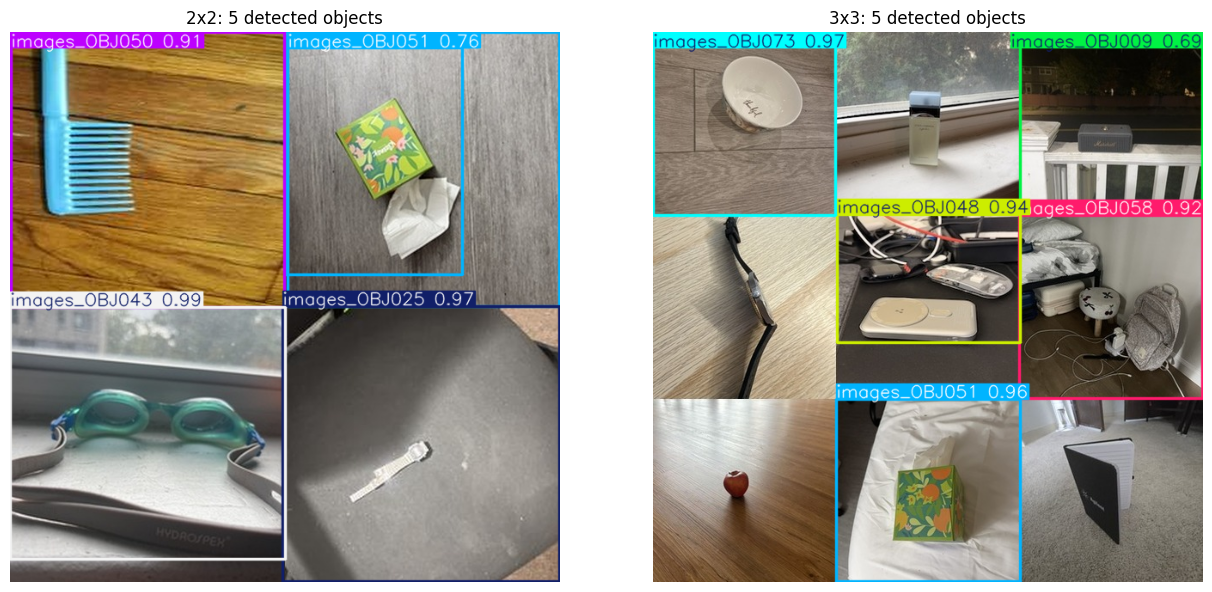

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, grid_size in zip(axes, [2, 3]):
    example = sorted((output / 'images' / 'test').glob(f'*_{grid_size}x{grid_size}.jpg'))[-1]
    result = best_model.predict(source=str(example), imgsz=640, conf=0.25, verbose=False)[0]
    ax.imshow(result.plot()[:, :, ::-1])
    ax.set_title(f'{grid_size}x{grid_size}: {len(result.boxes)} detected objects')
    ax.axis('off')
    print(f'\n{grid_size}x{grid_size} — {example.name}')
    for box in result.boxes:
        label = classes[int(box.cls.item())]
        xyxy = [round(v) for v in box.xyxy[0].tolist()]
        print(label, f'confidence={box.conf.item():.2f}', f'box={xyxy}')
plt.tight_layout()
plt.show()


## 9. Training graphs

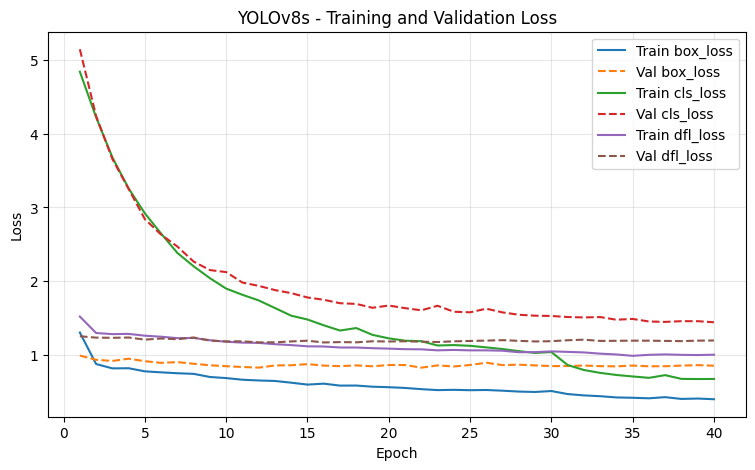

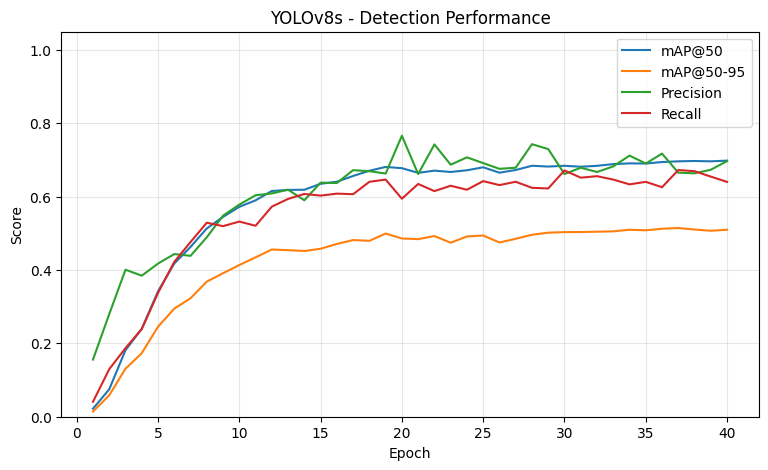

confusion_matrix.png


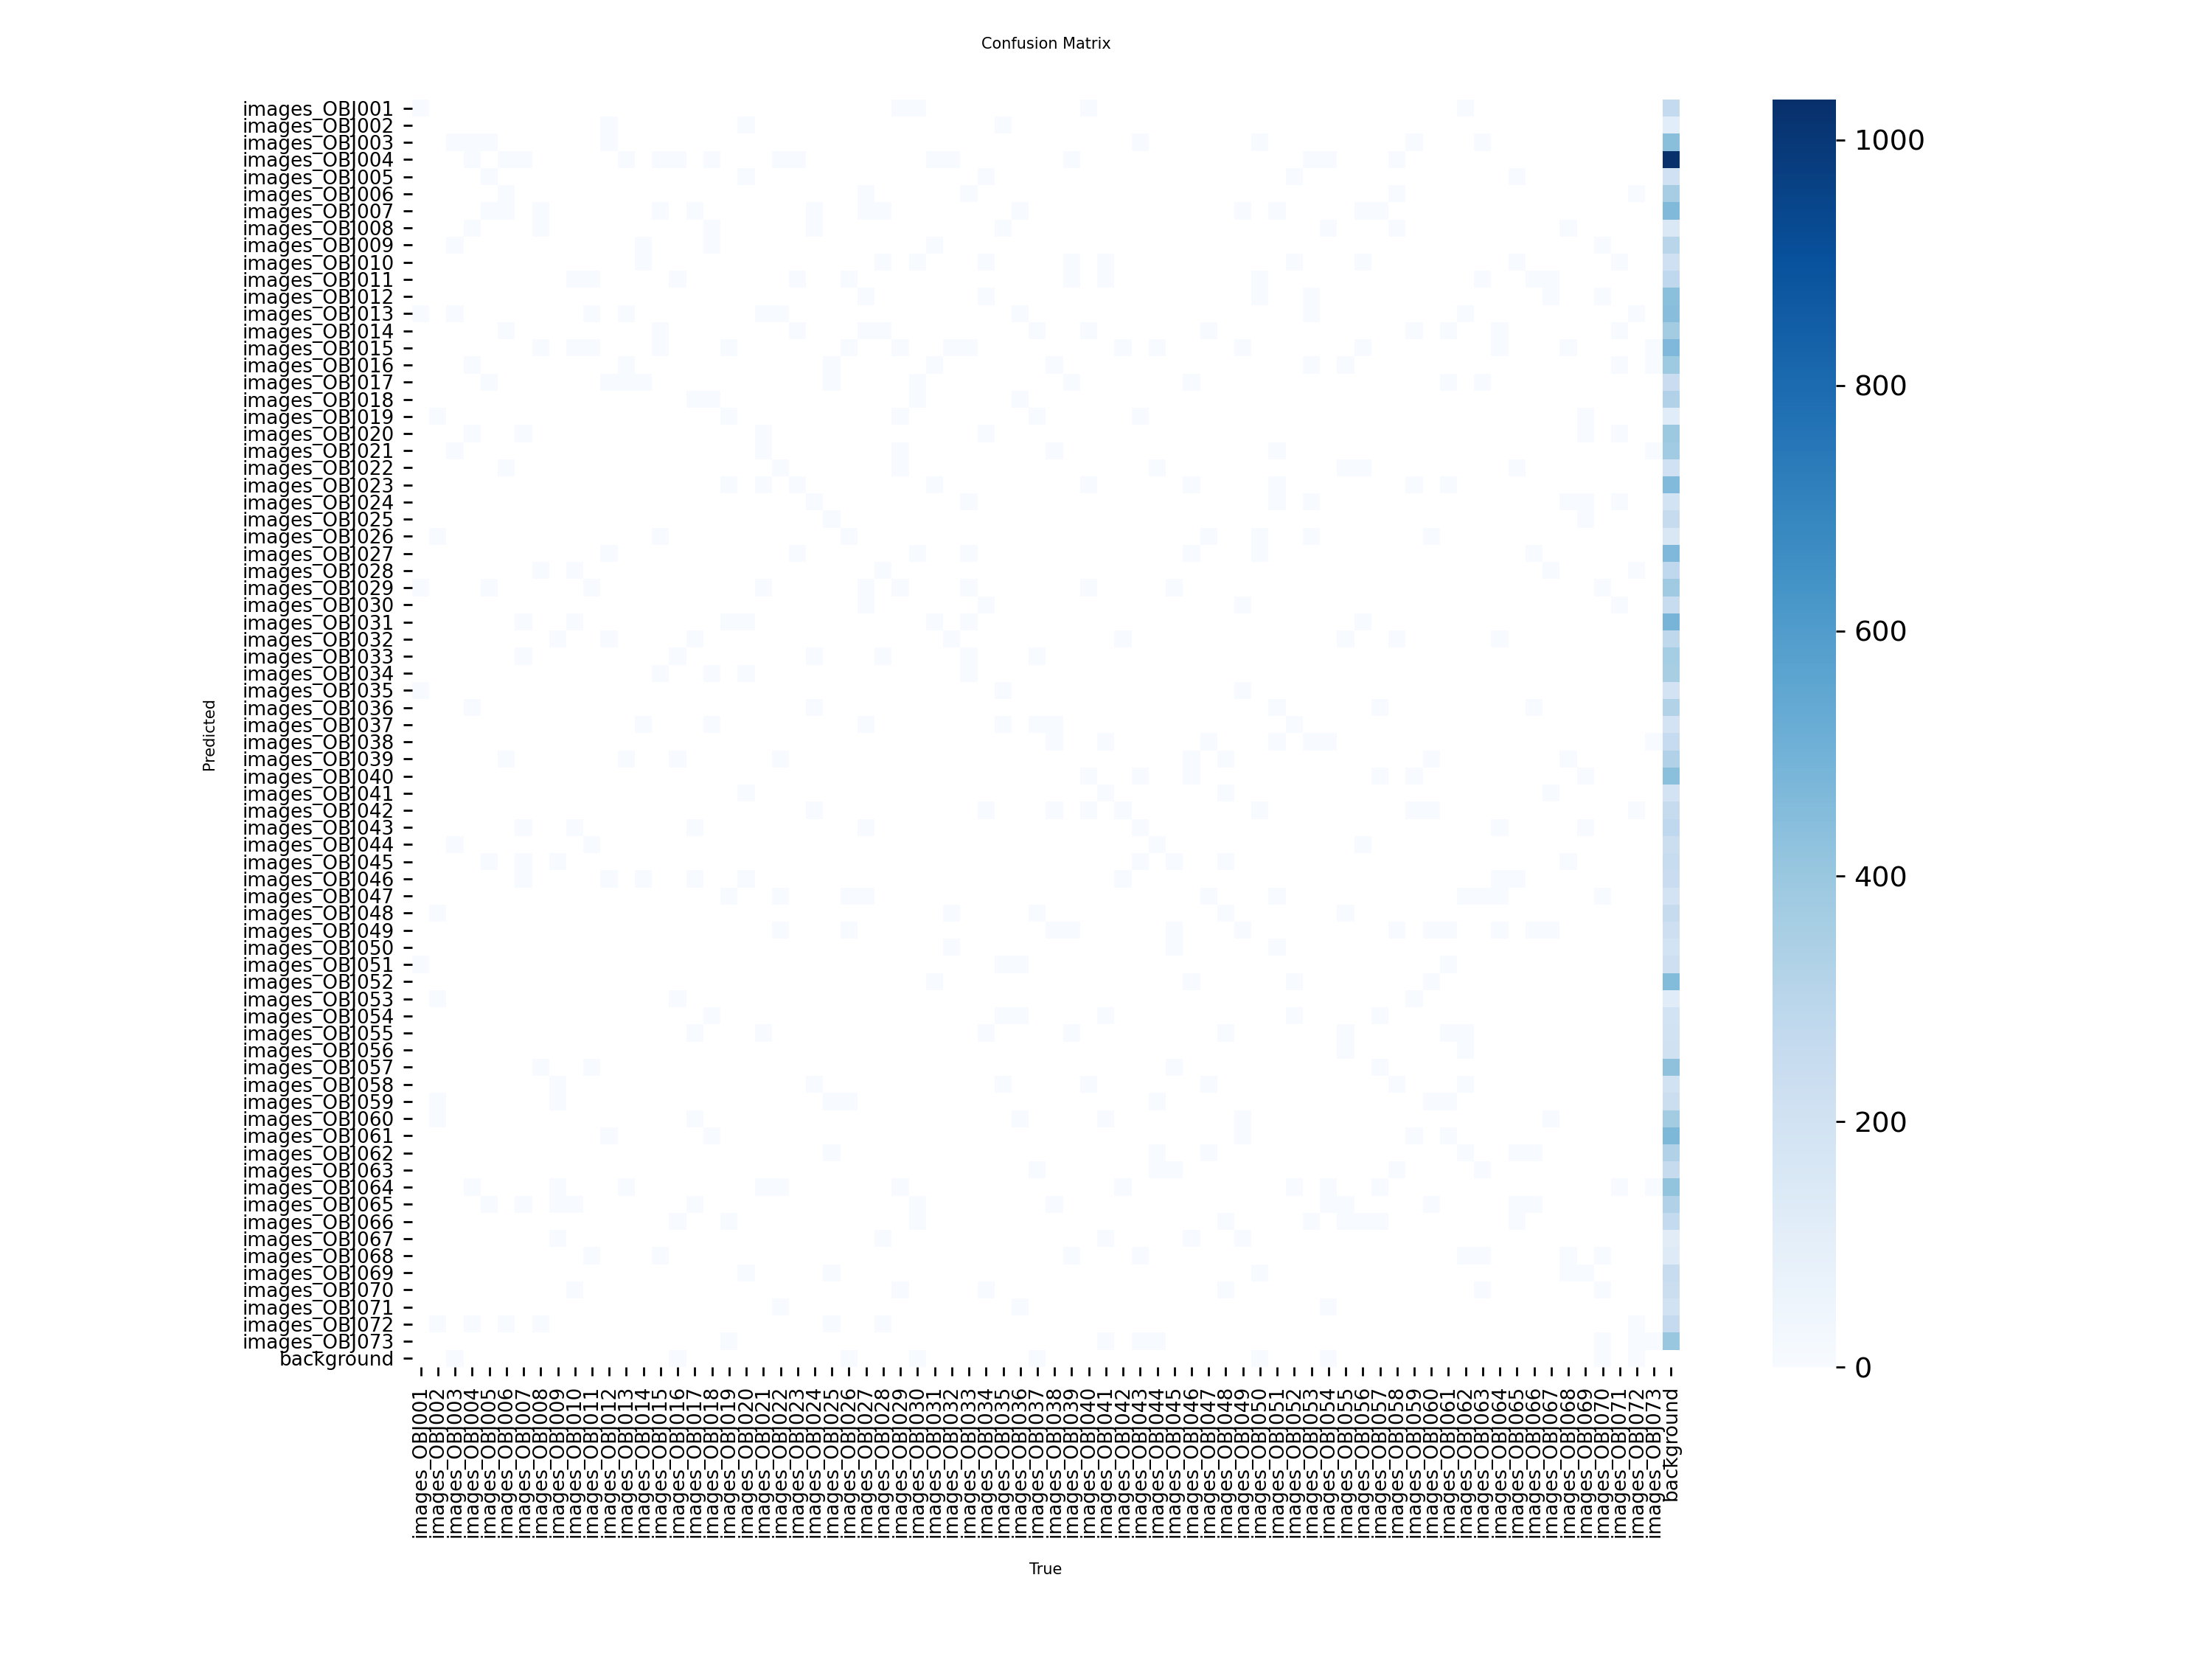

BoxPR_curve.png


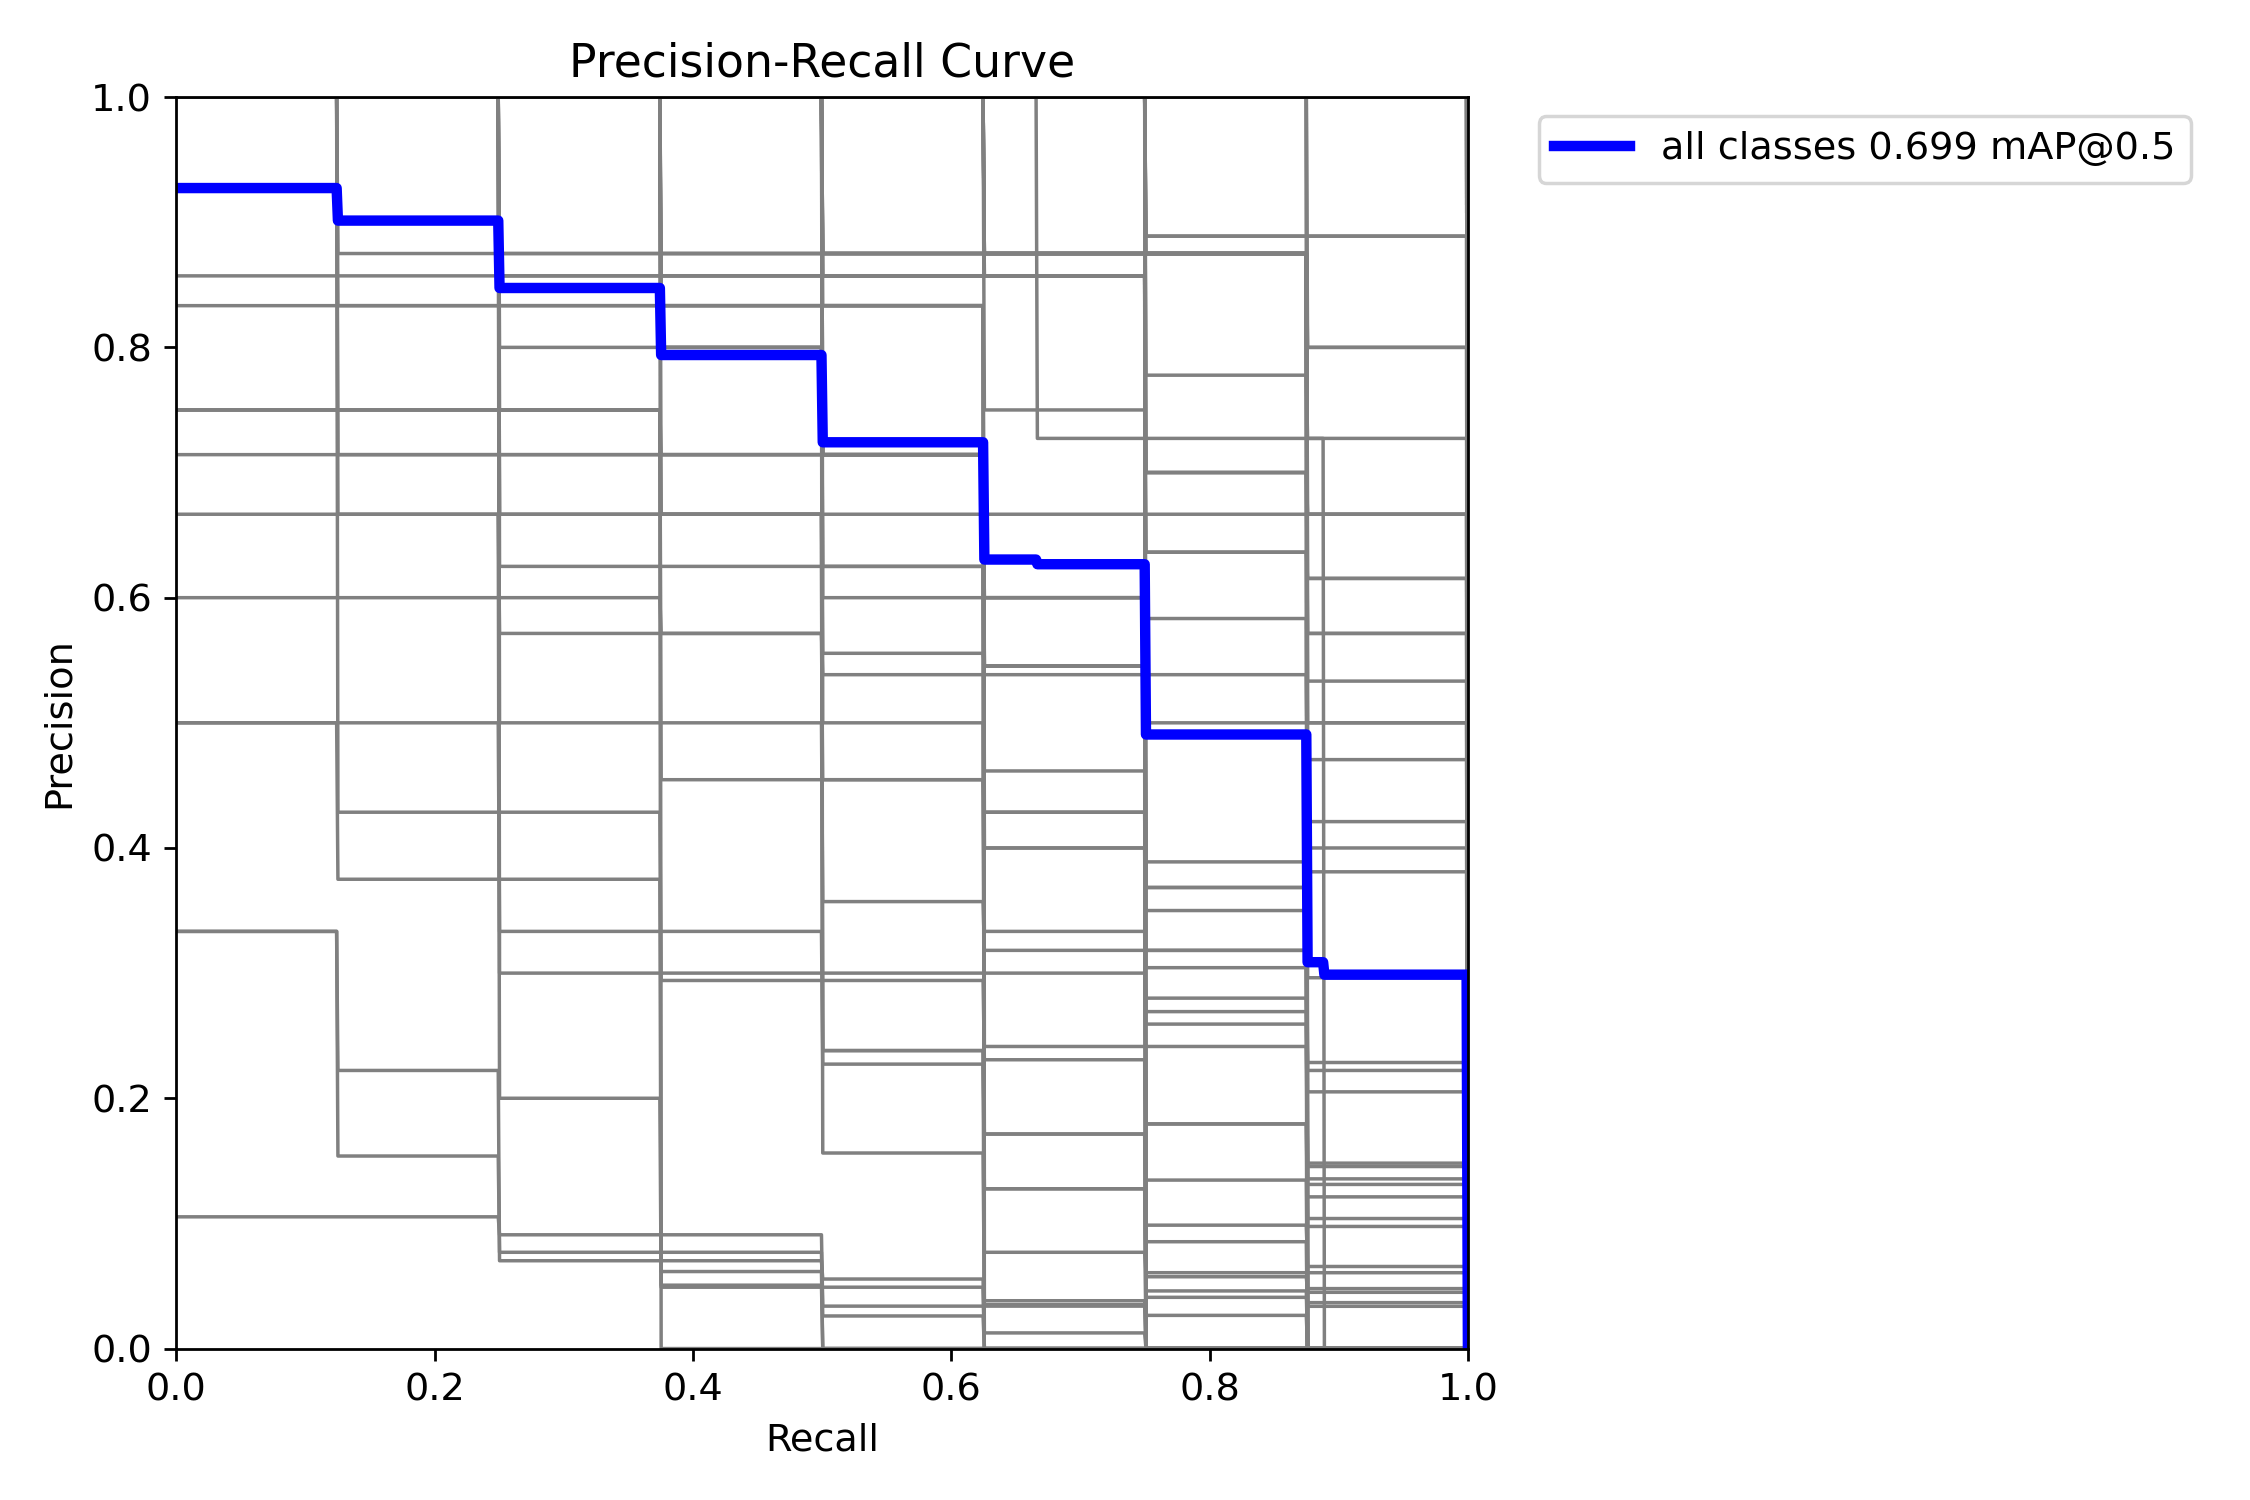

BoxF1_curve.png


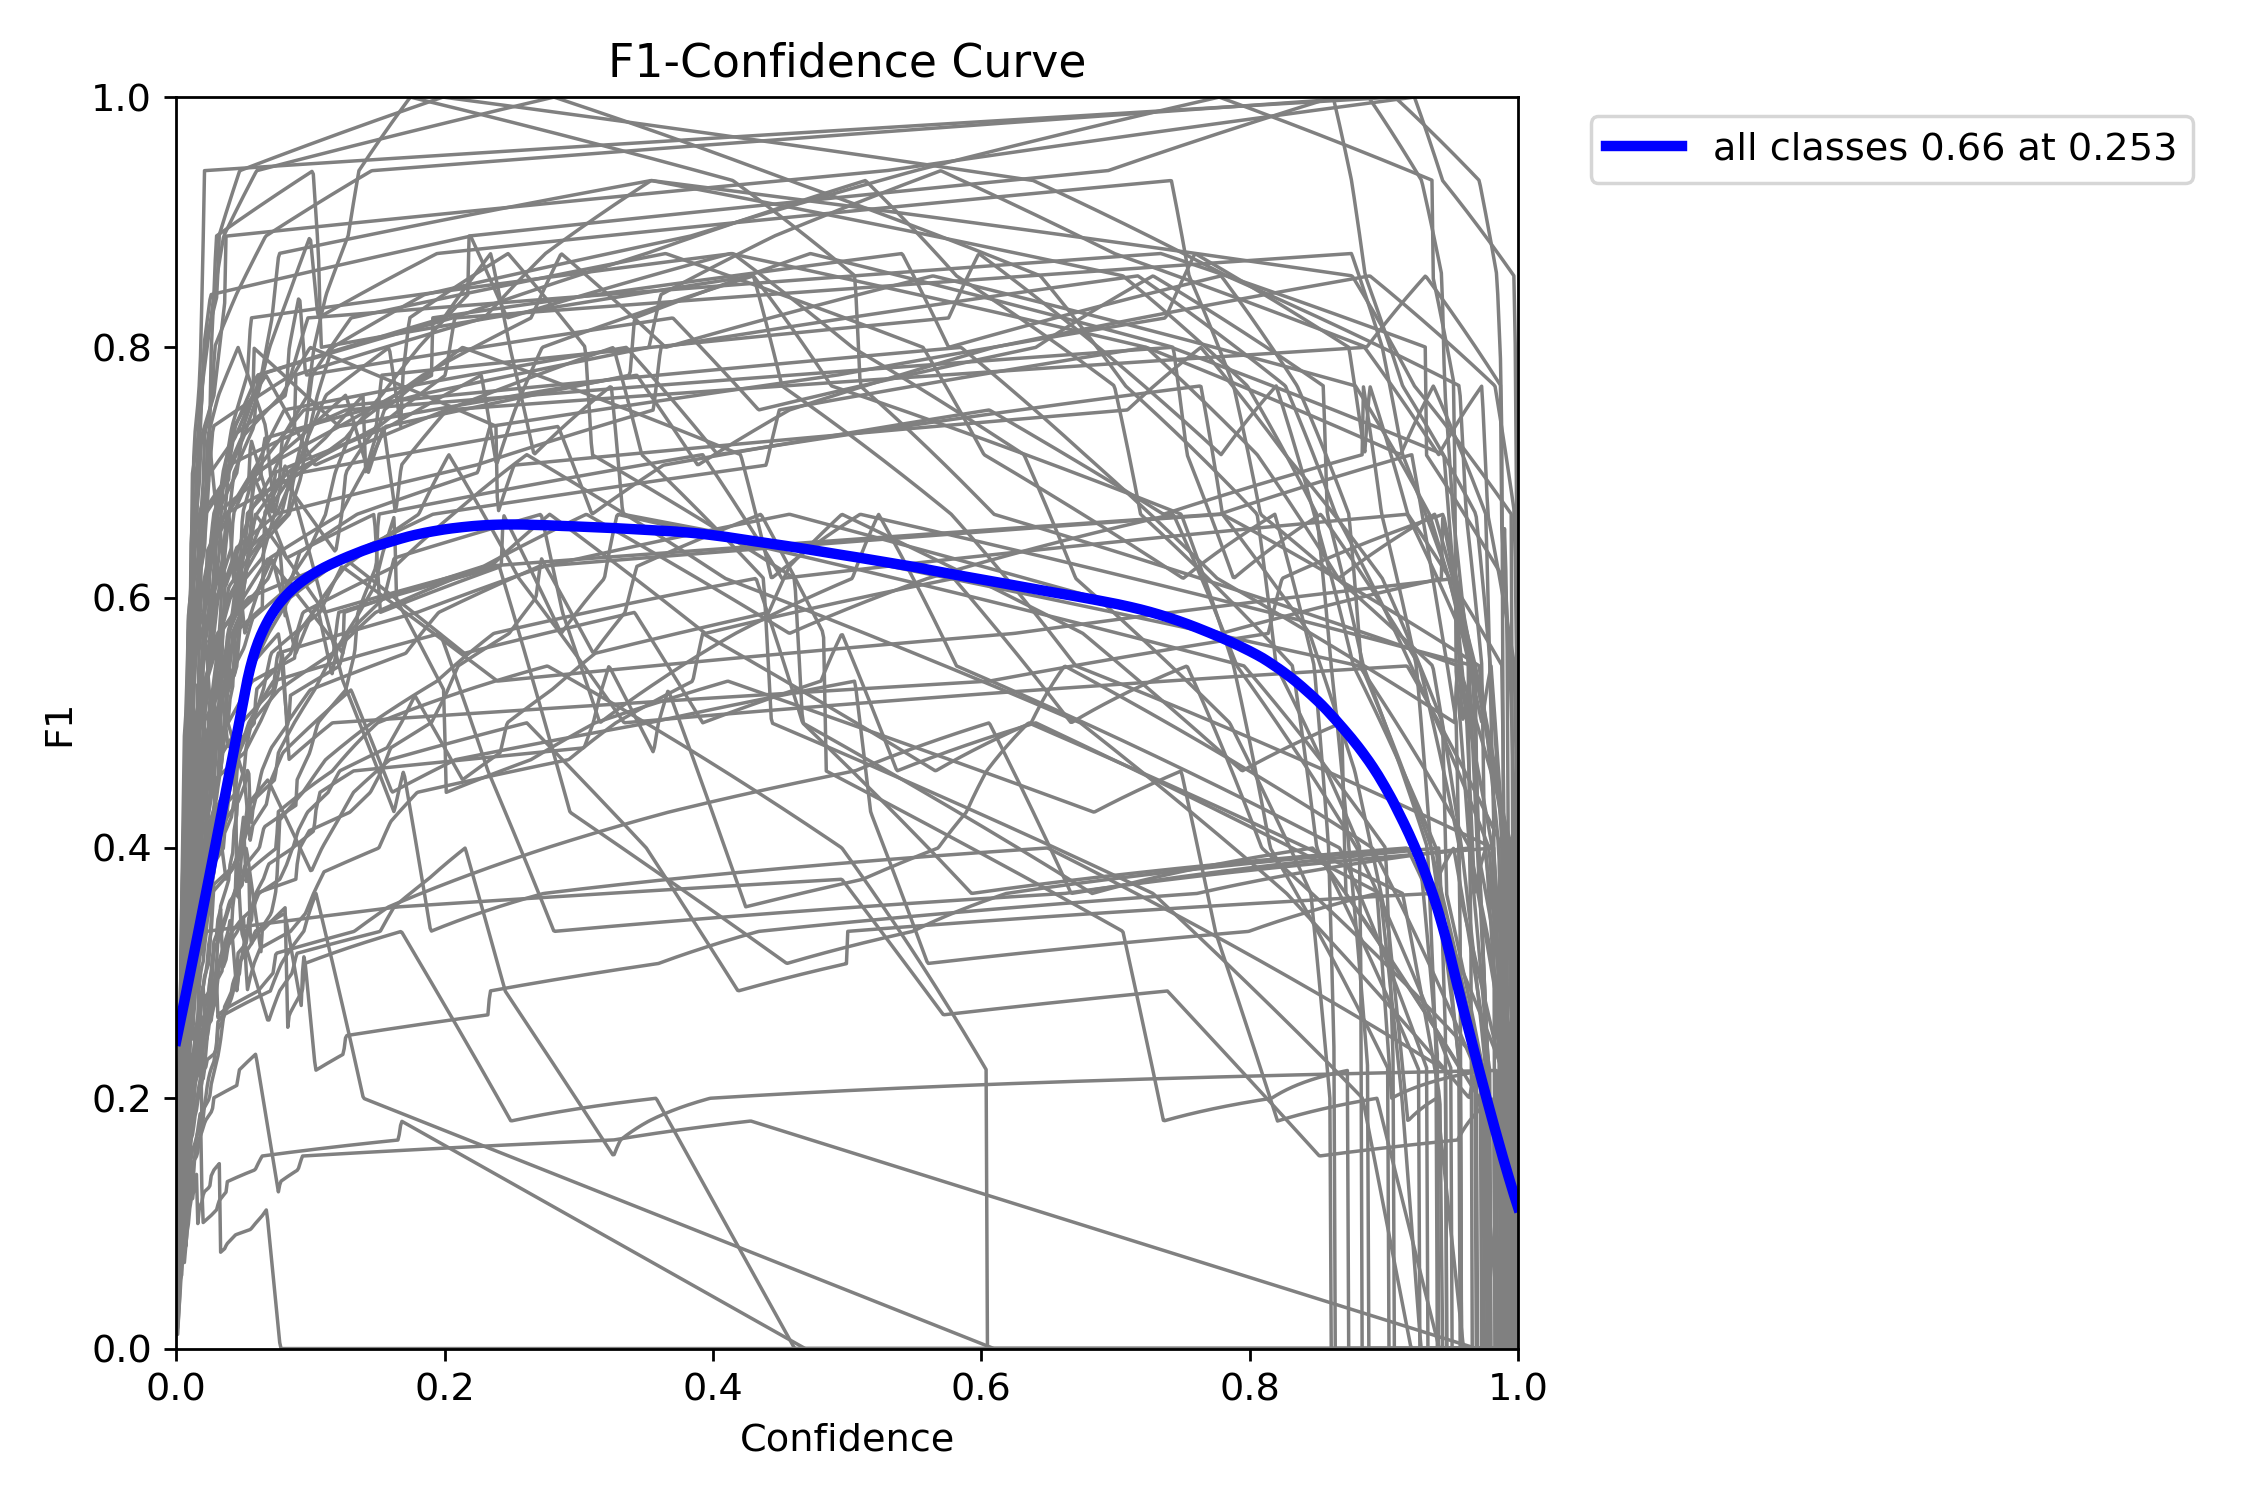

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPImage
from pathlib import Path

# Locate the completed YOLO training run
run_dir = Path(model.trainer.save_dir)
df = pd.read_csv(run_dir / "results.csv")
df.columns = df.columns.str.strip()

# 1. Training and validation loss
plt.figure(figsize=(9, 5))

for metric in ["box_loss", "cls_loss", "dfl_loss"]:
    train_col = f"train/{metric}"
    val_col = f"val/{metric}"

    if train_col in df:
        plt.plot(df["epoch"], df[train_col],
                 label=f"Train {metric}")

    if val_col in df:
        plt.plot(df["epoch"], df[val_col],
                 linestyle="--", label=f"Val {metric}")

plt.title("YOLOv8s - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 2. Detection performance
plt.figure(figsize=(9, 5))

metrics = {
    "metrics/mAP50(B)": "mAP@50",
    "metrics/mAP50-95(B)": "mAP@50-95",
    "metrics/precision(B)": "Precision",
    "metrics/recall(B)": "Recall"
}

for column, label in metrics.items():
    if column in df:
        plt.plot(df["epoch"], df[column], label=label)

plt.title("YOLOv8s - Detection Performance")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 3. Other important evaluation graphs
for filename in [
    "confusion_matrix.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png"
]:
    path = run_dir / filename

    if path.exists():
        print(filename)
        display(IPImage(filename=str(path), width=850))

In [11]:
!pip install -q gradio
import gradio as gr
from ultralytics import YOLO

model = YOLO(str(best_path))

def take_attendance(img):
    r = model.predict(img, conf=0.25)[0]
    present = sorted({model.names[int(c)] for c in r.boxes.cls})
    return r.plot()[:, :, ::-1], f"Present ({len(present)}): " + ", ".join(present)

gr.Interface(take_attendance, gr.Image(type="pil"), [gr.Image(), gr.Textbox()]).launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b705233bf347f45918.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
